In [1]:
import scanpy as sc
import scanpy.external as sce

import pandas as pd
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
import anndata as ad

from copy import deepcopy

# sc.logging.print_version()
sc.settings.verbosity = 3
sc.set_figure_params(figsize=(5,5))

import chronopack as cp


Matplotlib is building the font cache; this may take a moment.


In [2]:
import os
from pathlib import Path

# Folder holding one sub-folder per experiment; see analyses/README.md.
DATA_DIR = Path(os.environ.get("CHRONOPACK_DATA_DIR", "../data"))
EXP_DIR = DATA_DIR / "k562-tnfa.hg38.rep"
for sub in ("intmd", "output"):
    (EXP_DIR / sub).mkdir(parents=True, exist_ok=True)

# Create AnnData object

In [3]:
sample_paths = [
    '../inputs/k562-tnfa.hg38.rep/N701_scK562_TNFA_Replication_RT_1.aligned.sorted.merged.tagged.dge.time_tags.csv.gz',
    '../inputs/k562-tnfa.hg38.rep/N702_scK562_TNFA_Replication_RT_2.aligned.sorted.merged.tagged.dge.time_tags.csv.gz',
    '../inputs/k562-tnfa.hg38.rep/N703_scK562_TNFA_Replication_RT_3.aligned.sorted.merged.tagged.dge.time_tags.csv.gz',
    '../inputs/k562-tnfa.hg38.rep/N704_scK562_TNFA_Replication_RT_4.aligned.sorted.merged.tagged.dge.time_tags.csv.gz',
]
# Download any of these files missing from ../inputs/ from ArrayExpress (E-MTAB-15894); files already there are used as they are.
cp.io.download_arrayexpress_files("E-MTAB-15894", sample_paths)

adata = cp.io.read_time_tagged_dge(sample_paths, sample_names=['N701', 'N702', 'N703', 'N704'])
print(adata)


AnnData object with n_obs × n_vars = 7646 × 27942
    obs: 'COUNTS', 'sample', 'time', 'time_group'
    uns: 'chronopack'


# QC & preprocessing

AnnData object with n_obs × n_vars = 7164 × 20036
    obs: 'COUNTS', 'sample', 'time', 'time_group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb'
    var: 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'chronopack'


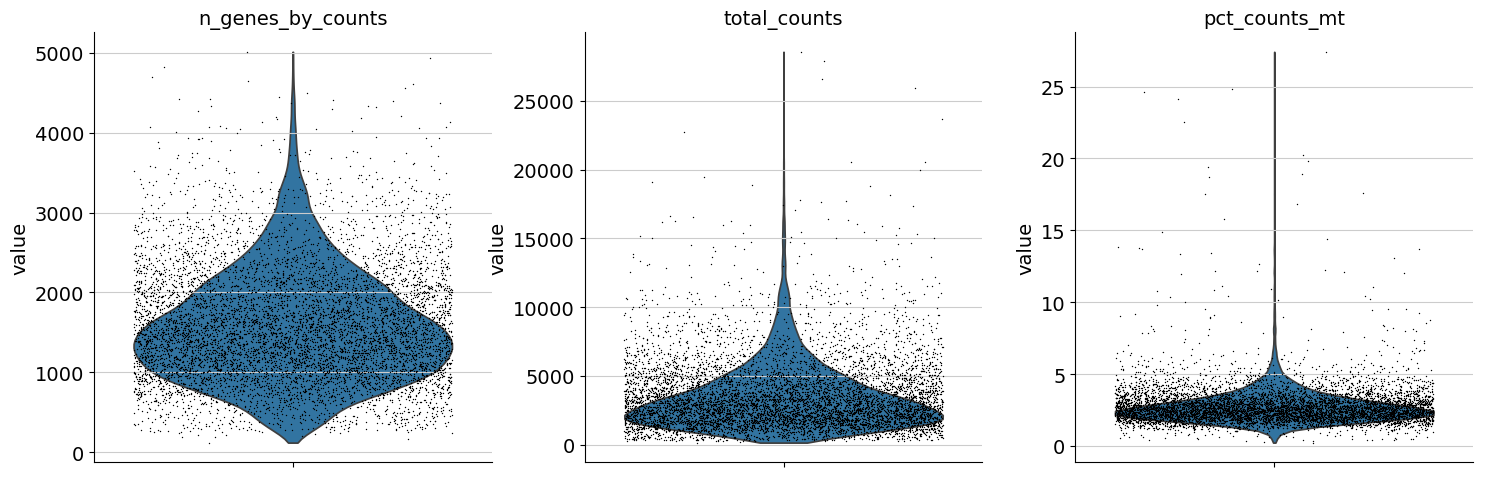

In [4]:
adata.var['mt'] = adata.var_names.str.startswith(('MT-', 'mt-'))
adata.var['rb'] = adata.var_names.str.startswith(('RPS', 'RPL'))
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt', 'rb'], percent_top=None, log1p=False, inplace=True)
sc.pl.violin(adata, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'], jitter=0.4, multi_panel=True)

qc_mask = (
    (adata.obs['total_counts'] >= 500)
    & (adata.obs['total_counts'] <= 15000)
    & (adata.obs['pct_counts_mt'] < 5)
    & (adata.obs['n_genes_by_counts'] >= 500)
)
adata = adata[qc_mask, :].copy()
sc.pp.filter_genes(adata, min_cells=3)
print(adata)


In [5]:
sc.pp.scrublet(adata, batch_key="sample")
adata = adata[~adata.obs['predicted_doublet'], :]


# Standard processing

In [6]:
cell_cycle_genes = [x.strip() for x in open('../resources/regev_lab_cell_cycle_genes.txt')]
s_genes = cell_cycle_genes[:43]
g2m_genes = cell_cycle_genes[43:]
cell_cycle_genes = [x for x in cell_cycle_genes if x in adata.var_names]


In [7]:
adata.layers['counts'] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
adata.layers['cpm'] = adata.X.copy()
sc.pp.log1p(adata)
adata.layers['log1p'] = adata.X.copy()

sc.pp.highly_variable_genes(adata, batch_key='sample', n_top_genes=3000)
sc.tl.score_genes_cell_cycle(adata, s_genes=s_genes, g2m_genes=g2m_genes)
adata_hvg = adata[:, adata.var.highly_variable]
bck = adata_hvg.copy()


01_PreprocessDatasets.ipynb:cell-9:1: ImplicitModificationWarning: Setting element `.layers['counts']` of view, initializing view as actual.


/new-stg/home/alex/miniconda3/envs/chronopack-install-test/lib/python3.11/site-packages/anndata/_core/anndata.py:1138: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/new-stg/home/alex/miniconda3/envs/chronopack-install-test/lib/python3.11/site-packages/scanpy/preprocessing/_simple.py:666: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 2, 'C', False, aligned=True))
  data[i] -= regressor[i] @ coeff
/new-stg/home/alex/miniconda3/envs/chronopack-install-test/lib/python3.11/site-packages/scanpy/preprocessing/_simple.py:666: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 2, 'C', False, aligned=True))
  data[i] -= regressor[i] @ coeff
01_PreprocessDatasets.ipynb:cell-10:8: FutureWarning: In the future, the default backend for leiden will be igraph instead o

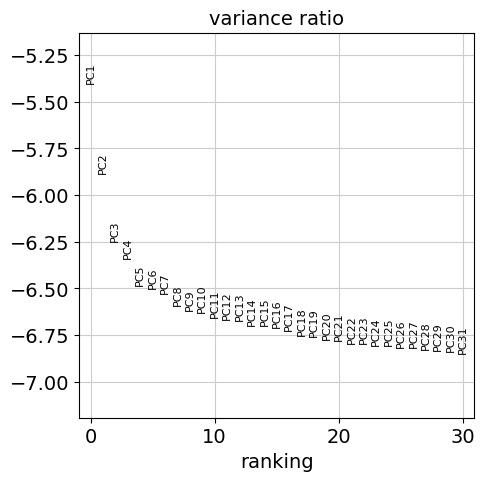

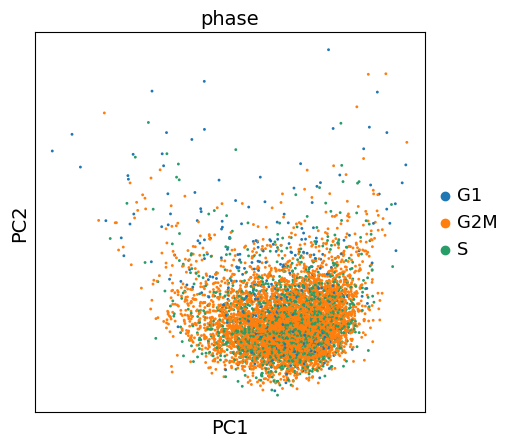

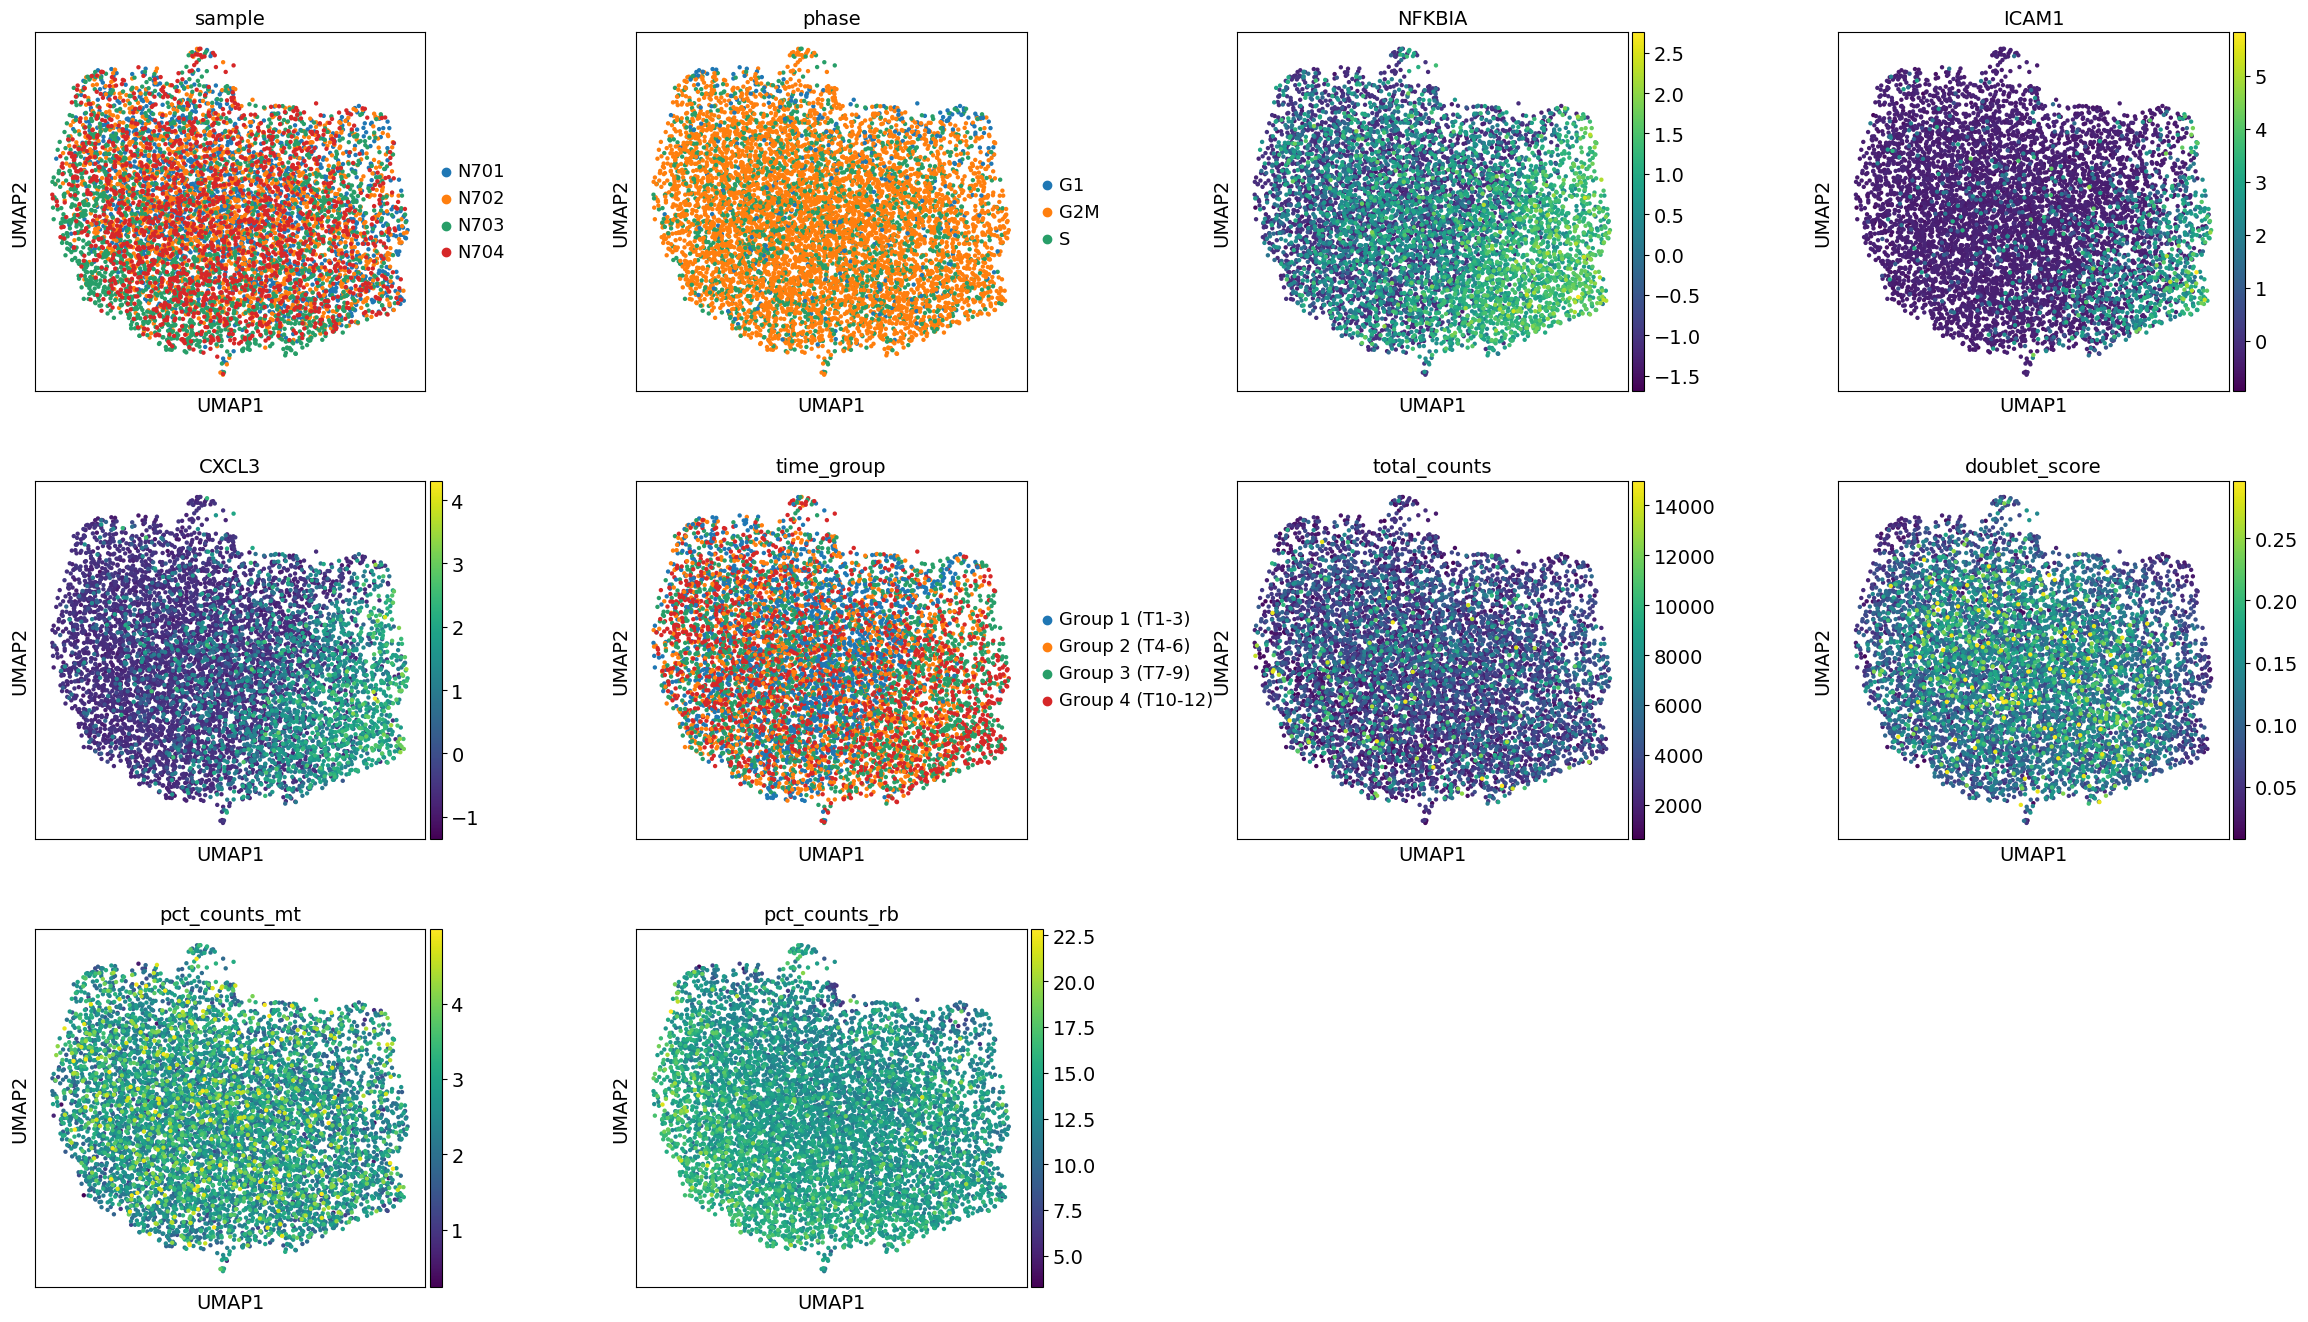

In [8]:
sc.pp.regress_out(adata_hvg, ['total_counts', 'pct_counts_mt', 'S_score', 'G2M_score'])
sc.pp.scale(adata_hvg)
sc.tl.pca(adata_hvg, n_comps=50, svd_solver='arpack')
sc.pl.pca_variance_ratio(adata_hvg, n_pcs=30, log=True)
sc.pp.neighbors(adata_hvg, n_pcs=12)

sc.tl.umap(adata_hvg)
sc.tl.leiden(adata_hvg, resolution=0.1, key_added='leiden_unintegrated')

sc.pl.pca_scatter(adata_hvg, color='phase')
sc.pl.umap(adata_hvg, color=['sample', 'phase', 'NFKBIA', 'ICAM1', 'CXCL3', 'time_group', 'total_counts', 'doublet_score', 'pct_counts_mt', 'pct_counts_rb'], wspace=0.4, size=40, ncols=4)


# Batch effect correction w/ComBat

In [9]:
df = adata.obs[['time', 'sample']]
table = pd.crosstab(df['time'], df['sample'])
print(table)


sample  N701  N702  N703  N704
time                          
1        189   157   164   166
2        199   180   174   148
3        131   112   113   126
4        139   163   139   152
5        134    93   127   108
6        100   113    98   106
7        201   190   215   190
8        165   166   165   143
9        136   130   123   129
10       152   176   162   131
11       134   142   172   166
12       166   146   145   155


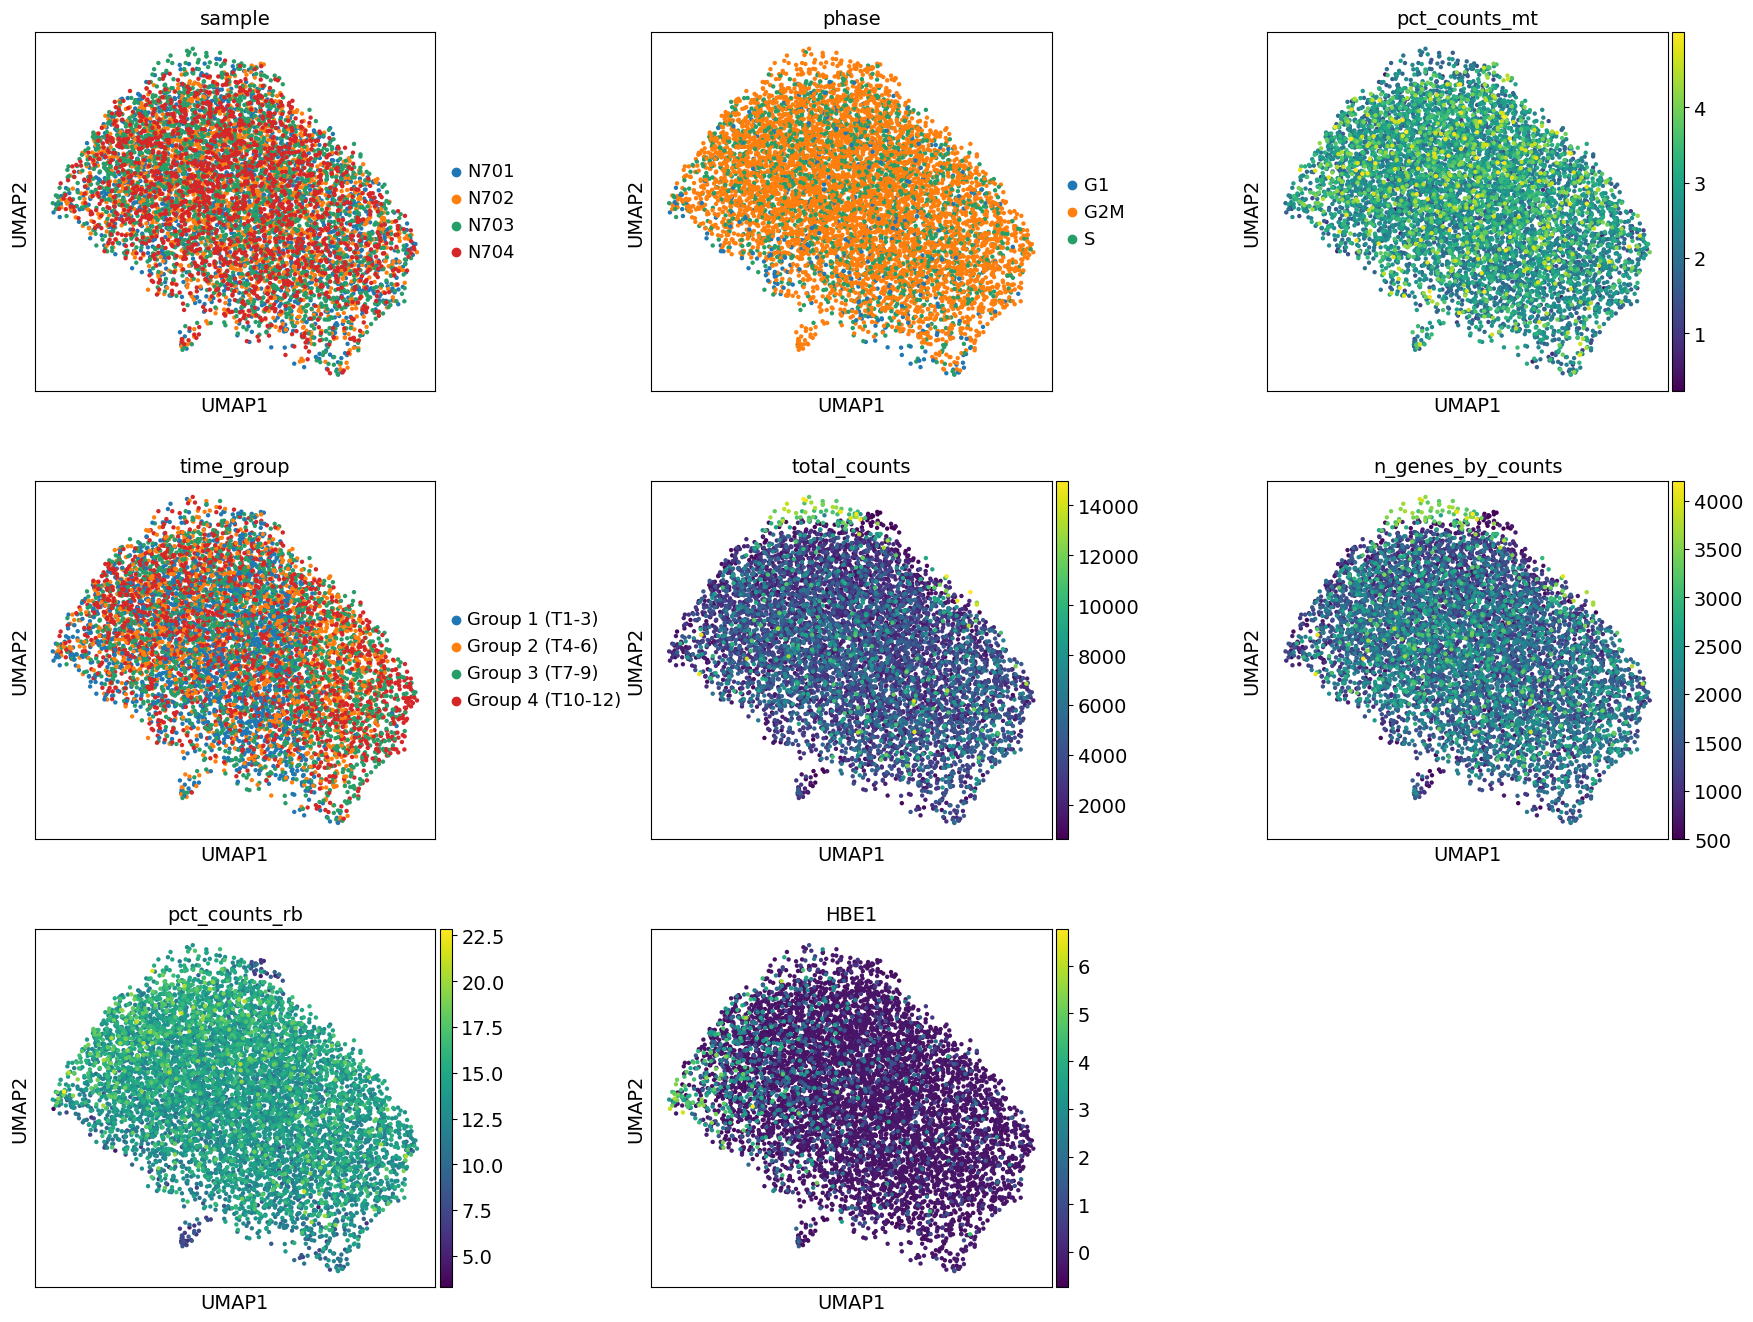

In [10]:
adata_hvg = bck.copy()

sc.pp.regress_out(adata_hvg, keys=['total_counts', 'pct_counts_mt', 'S_score', 'G2M_score']) # Remove QC + cell-cycle effects first
sc.pp.combat(adata_hvg, key='sample') # Batch correction on (log1p + residual) expression
adata_hvg.layers['corrected'] = adata_hvg.X.copy()

sc.pp.scale(adata_hvg, max_value=10)
sc.tl.pca(adata_hvg, n_comps=50)
sc.pp.neighbors(adata_hvg, n_neighbors=15, n_pcs=30)
sc.tl.umap(adata_hvg)
sc.pl.umap(adata_hvg, color=['sample', 'phase', 'pct_counts_mt', 'time_group', 'total_counts', 'n_genes_by_counts', 'pct_counts_rb', 'HBE1'], wspace=0.4, size=40, ncols=3)


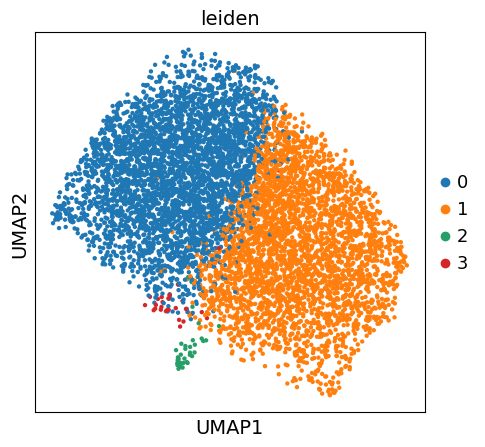

In [11]:
sc.tl.leiden(adata_hvg, resolution=0.5)
sc.pl.umap(adata_hvg, color=['leiden'], wspace=0.4, size=40, ncols=3)


Next, we remove the two clusters of low-quality cells identified in the manuscript analysis (Leiden cluster `2` at resolution 0.5, then cluster `6` at resolution 1.0). The removals are applied by barcode from `exclude_leiden_clusters.manuscript.csv`, so the retained cells do not depend on the Leiden implementation version (leidenalg 0.10 and 0.12 number these clusters differently).

/new-stg/home/alex/miniconda3/envs/chronopack-install-test/lib/python3.11/site-packages/scanpy/tools/_leiden.py:196: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[key_added] = pd.Categorical(


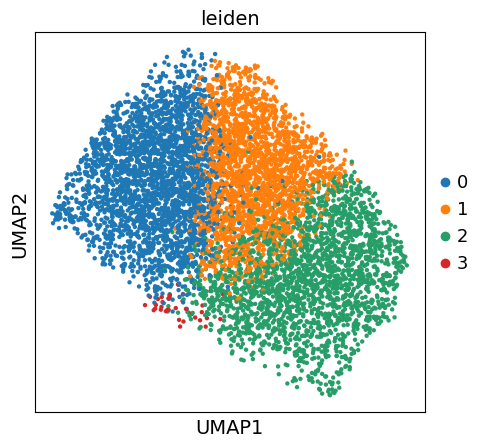

In [12]:
manuscript_exclusions = pd.read_csv('exclude_leiden_clusters.manuscript.csv')
excluded = manuscript_exclusions.loc[manuscript_exclusions['removed_at'] == 'leiden_r0.5_cluster2', 'cell_id']
assert excluded.isin(adata_hvg.obs_names).all(), 'manuscript barcodes missing from adata_hvg'
adata_hvg = adata_hvg[~adata_hvg.obs_names.isin(excluded), :]
sc.tl.leiden(adata_hvg, resolution=0.7)
sc.pl.umap(adata_hvg, color=['leiden'], wspace=0.4, size=40, ncols=3)


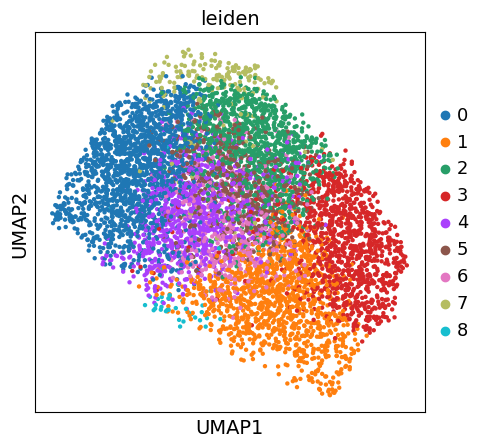

In [13]:
sc.tl.leiden(adata_hvg, resolution=1.0)
sc.pl.umap(adata_hvg, color=['leiden'], wspace=0.4, size=40, ncols=3)


/new-stg/home/alex/miniconda3/envs/chronopack-install-test/lib/python3.11/site-packages/scanpy/tools/_leiden.py:196: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[key_added] = pd.Categorical(


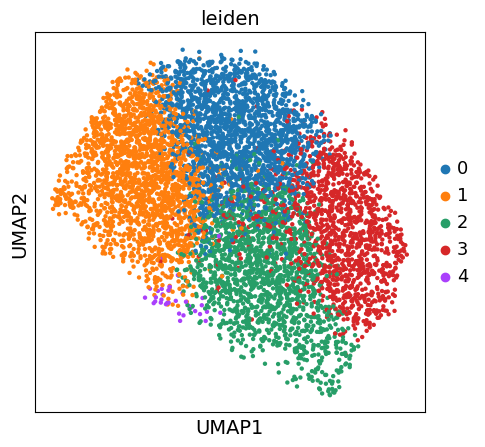

In [14]:
excluded = manuscript_exclusions.loc[manuscript_exclusions['removed_at'] == 'leiden_r1.0_cluster6', 'cell_id']
assert excluded.isin(adata_hvg.obs_names).all(), 'manuscript barcodes missing from adata_hvg'
adata_hvg = adata_hvg[~adata_hvg.obs_names.isin(excluded), :]
sc.tl.leiden(adata_hvg, resolution=0.7)
sc.pl.umap(adata_hvg, color=['leiden'], wspace=0.4, size=40, ncols=3)


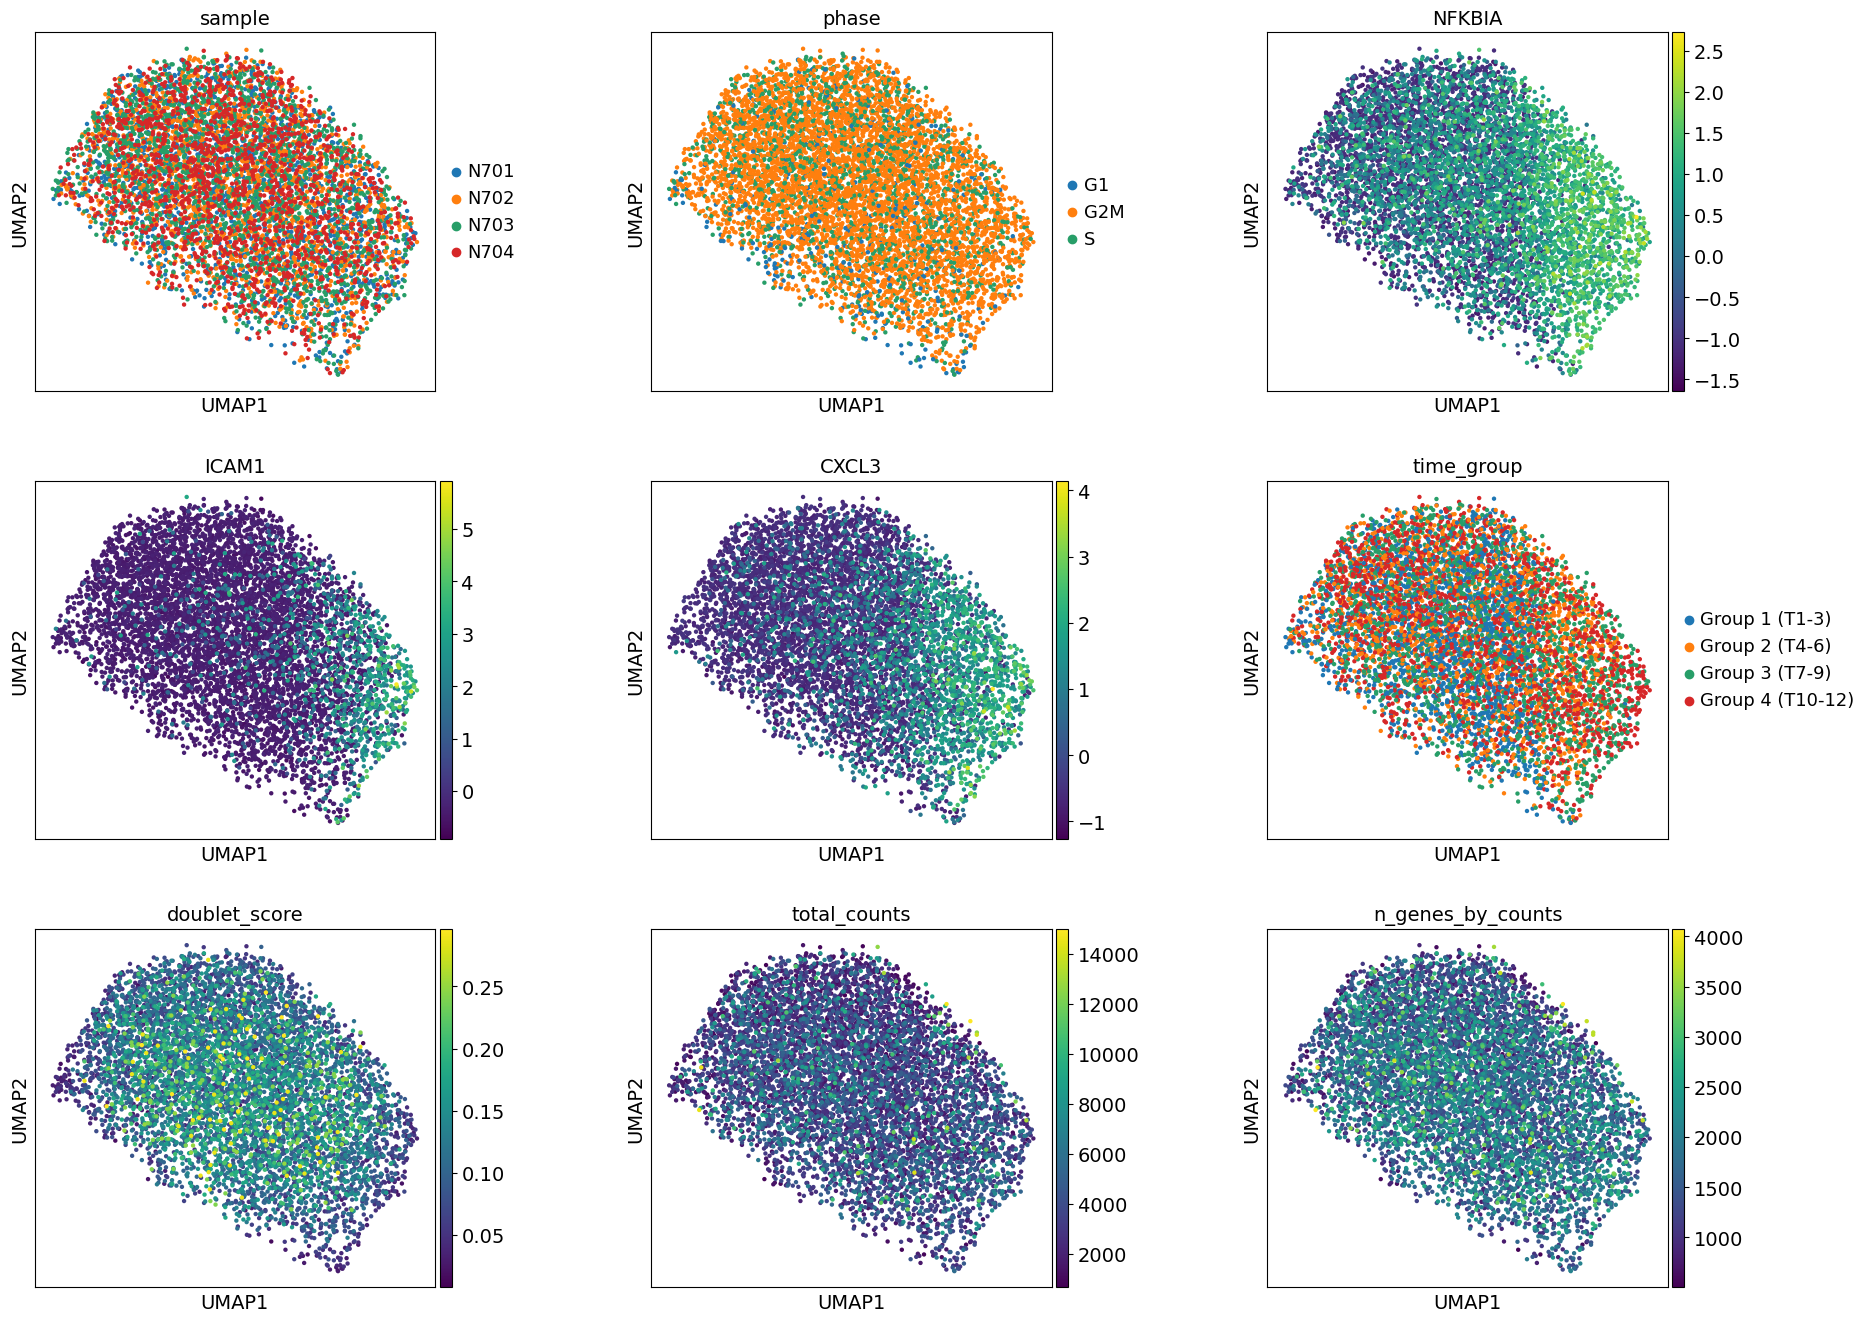

In [15]:
sc.pl.umap(adata_hvg, color=['sample', 'phase', 'NFKBIA', 'ICAM1', 'CXCL3', 'time_group', 'doublet_score', 'total_counts', 'n_genes_by_counts'], wspace=0.4, size=40, ncols=3)


# Save single-cell AnnData object

In [16]:
adata = adata[adata_hvg.obs.index, :]
adata.obsp = adata_hvg.obsp.copy()
adata.obsm = adata_hvg.obsm.copy()
adata.obs = adata_hvg.obs.copy()

print(adata)
print(adata_hvg)

adata.write_h5ad(EXP_DIR / 'output/adata_full.1e4-variant.chk0.h5ad')
adata_hvg.write_h5ad(EXP_DIR / 'output/adata_hvg.1e4-variant.chk0.h5ad')


AnnData object with n_obs × n_vars = 6857 × 20036
    obs: 'COUNTS', 'sample', 'time', 'time_group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'n_genes', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'leiden'
    var: 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'chronopack', 'scrublet', 'log1p', 'hvg'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts', 'cpm', 'log1p'
    obsp: 'distances', 'connectivities'
AnnData object with n_obs × n_vars = 6857 × 3000
    obs: 'COUNTS', 'sample', 'time', 'time_group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'n_genes', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'leiden'
    var: 'mt'